# EDA - RIDIRP

**Fuente:** Figshare, coleccion `6626162` - "Retinal Image Dataset of Infants and Retinopathy of Prematurity 2". DOI de coleccion `10.6084/m9.figshare.c.6626162.v1`. Paper asociado (DOI reportado por la propia API de Figshare como `resource_doi`): `10.1038/s41597-024-03409-7` (Scientific Data, 2024) - no verificado de forma independiente, ver `system/datasets_download/README.md`.

**Origen clinico:** cribado de ROP en el University Hospital Ostrava, Republica Checa.

**Contenido:** 188 recien nacidos, 6.004 imagenes retinianas organizadas en series longitudinales (multiples visitas por paciente), con metadatos clinicos por visita: sexo, edad gestacional (GA), peso al nacer (BW), edad postmenstrual (PMA) en esa visita puntual, codigo de diagnostico, forma de enfermedad Plus, y dispositivo de captura.

Este notebook explora el dataset **crudo**, tal como viene, antes de cualquier decision de mapeo/consenso (esas decisiones estan en `system/dataset_build/README.md`).

In [1]:
import re
import zipfile
import hashlib
from pathlib import Path
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path.cwd().resolve().parent.parent  # system/eda/ -> ROP_paper/
RAW_DIR = ROOT / "datasets" / "RIDIRP_Original"
EXTRACTED_DIR = ROOT / "datasets" / "extracted" / "RIDIRP" / "images_stack_without_captions"

plt.rcParams["figure.figsize"] = (8, 4)
pd.set_option("display.max_columns", 20)

In [2]:
db = pd.read_excel(RAW_DIR / "infant_retinal_database_info.xlsx", sheet_name="database")
print(db.head())
print("filas (visitas):", len(db), " | pacientes unicos:", db["ID"].nunique())

   ID SEX  GESTATIONAL AGE (GA)  BIRTH WEIGHT (BW)  POSTCONCEPTUAL AGE (PA)  \
0   1   F                    41               2905                44.000000   
1   1   F                    41               2905                47.000000   
2   1   F                    41               2905                50.000000   
3   2   M                    40               4040                41.000000   
4   2   M                    40               4040                43.285714   

   DIAGNOSIS CODE (DG)  PLUS FORM (PF)  DEVICE (D)  SERIE NUMBER (S)  
0                   11               0           1                 1  
1                   11               0           1                 2  
2                   11               0           1                 3  
3                   11               0           1                 1  
4                   11               0           1                 2  
filas (visitas): 484  | pacientes unicos: 188


In [3]:
# Hoja principal: una fila = una visita (serie) de un paciente
db.columns = ["id", "sex", "ga", "bw", "pma", "dg", "pf", "device", "series"] # series es como el numero de visitas que tiene un paciente, cada visita tiene varias imagenes
print("filas (visitas):", len(db), " | pacientes unicos:", db["id"].nunique())
db.head(20)

filas (visitas): 484  | pacientes unicos: 188


,id,sex,ga,bw,pma,dg,pf,device,series
0,1,F,41,2905,44.000000,11,0,1,1
1,1,F,41,2905,47.000000,11,0,1,2
2,1,F,41,2905,50.000000,11,0,1,3
3,2,M,40,4040,41.000000,11,0,1,1
4,2,M,40,4040,43.285714,11,0,1,2
5,2,M,40,4040,45.285714,11,0,1,3
6,3,F,41,3950,42.285714,11,0,1,1
7,3,F,41,3950,55.571429,11,0,1,2
8,4,F,41,3760,42.142857,11,0,1,1
9,4,F,41,3760,45.428571,11,0,1,2


In [4]:
# Hojas de diccionario: que significa cada codigo
diagnosis = pd.read_excel(RAW_DIR / "infant_retinal_database_info.xlsx", sheet_name="diagnosis")
plus_form = pd.read_excel(RAW_DIR / "infant_retinal_database_info.xlsx", sheet_name="plus_form")
devices = pd.read_excel(RAW_DIR / "infant_retinal_database_info.xlsx", sheet_name="devices")

display(diagnosis)
display(plus_form)
display(devices)

,DIAGNOSIS,DIAGNOSIS_ID,DESCRIPTION
0,physiological,0,physiological
1,ROP 0,1,retinopathy of prematurity stage 0
2,ROP 1,2,retinopathy of prematurity stage 1
3,ROP 2,3,retinopathy of prematurity stage 2
4,ROP 3,4,retinopathy of prematurity stage 3
5,ROP 4A,5,retinopathy of prematurity stage 4a
6,ROP 4B,6,retinopathy of prematurity stage 4b
7,ROP 5,7,retinopathy of prematurity stage 5
8,AP - ROP,8,aggressive posterior retinopathy of prematurity
9,st.p. ROP,9,status post retinopathy of prematurity


,PLUS FORM,PLUS FORM ID
0,normal,0
1,pre-plus,1
2,plus,2


,DEVICE,DEVICE ID
0,Clarity RetCam 3,1
1,Phoenix ICON,2
2,Natus RetCam Envision,3


## Profundidad longitudinal: visitas por paciente

RIDIRP es la unica de las 4 fuentes con densidad temporal real (multiples visitas del mismo paciente con PMA creciente). Verificamos cuanta profundidad hay realmente.

count    188.000000
mean       2.574468
std        2.007949
min        1.000000
25%        1.000000
50%        2.000000
75%        3.000000
max       16.000000
dtype: float64


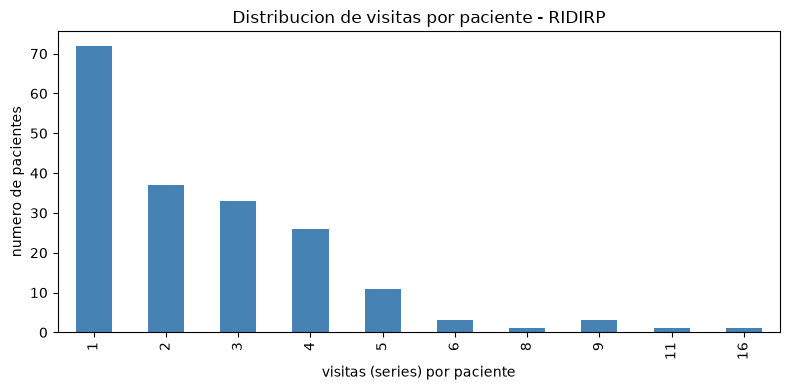

In [5]:
visits_per_patient = db.groupby("id").size()
print(visits_per_patient.describe())

fig, ax = plt.subplots()
visits_per_patient.value_counts().sort_index().plot(kind="bar", ax=ax, color="steelblue")
ax.set_xlabel("visitas (series) por paciente")
ax.set_ylabel("numero de pacientes")
ax.set_title("Distribucion de visitas por paciente - RIDIRP")
plt.tight_layout()
plt.show()

In [6]:
# Caso extremo real: paciente 43 (GA 24, BW 550g - muy prematuro), diagnostico AP-ROP (dg=8)
# 16 visitas reales siguiendo la progresion de la enfermedad semana a semana.
p43 = db[db["id"] == 43].sort_values("pma")
p43

,id,sex,ga,bw,pma,dg,pf,device,series
111,43,F,24,550,32.428571,8,2,1,1
112,43,F,24,550,32.857143,8,2,1,2
113,43,F,24,550,33.428571,8,2,1,3
114,43,F,24,550,34.857143,8,2,1,4
115,43,F,24,550,35.714286,8,2,1,5
116,43,F,24,550,36.428571,8,2,1,6
117,43,F,24,550,38.714286,8,2,1,7
118,43,F,24,550,38.857143,8,2,1,8
119,43,F,24,550,39.714286,8,2,1,9
120,43,F,24,550,40.714286,8,2,1,10


### Todos los pacientes con mas de 5 visitas (no solo el caso 43)

Antes de decidir si son "outliers" a excluir, veamos quienes son y que trayectoria clinica tienen.

In [7]:
UMBRAL_VISITAS = 5

many_visits = visits_per_patient[visits_per_patient > UMBRAL_VISITAS].sort_values(ascending=False)
print(f"Pacientes con mas de {UMBRAL_VISITAS} visitas: {len(many_visits)} de {len(visits_per_patient)}")
print(many_visits)

Pacientes con mas de 5 visitas: 9 de 188
id
43     16
139    11
138     9
55      9
31      9
52      8
7       6
84      6
66      6
dtype: int64


In [8]:
dg_names = dict(zip(diagnosis["DIAGNOSIS_ID"], diagnosis["DIAGNOSIS"]))  # definido aqui para no depender del orden de celdas de abajo

for pid in many_visits.index:
    sub = db[db["id"] == pid].sort_values("pma").copy()
    sub["diagnostico"] = sub["dg"].map(dg_names)
    print(f"\n=== Paciente {pid} | GA={sub['ga'].iloc[0]} sem | BW={sub['bw'].iloc[0]} g | {len(sub)} visitas ===")
    display(sub[["series", "pma", "diagnostico", "pf", "device"]])


=== Paciente 43 | GA=24 sem | BW=550 g | 16 visitas ===


,series,pma,diagnostico,pf,device
111,1,32.428571,AP - ROP,2,1
112,2,32.857143,AP - ROP,2,1
113,3,33.428571,AP - ROP,2,1
114,4,34.857143,AP - ROP,2,1
115,5,35.714286,AP - ROP,2,1
116,6,36.428571,AP - ROP,2,1
117,7,38.714286,AP - ROP,2,1
118,8,38.857143,AP - ROP,2,1
119,9,39.714286,AP - ROP,2,1
120,10,40.714286,AP - ROP,2,1



=== Paciente 139 | GA=24 sem | BW=550 g | 11 visitas ===


,series,pma,diagnostico,pf,device
404,1,31.0,physiological,0,2
405,2,33.0,ROP 0,0,2
406,3,34.0,ROP 1,0,2
407,4,35.0,ROP 2,2,2
408,5,35.0,ROP 2,2,2
409,6,36.0,st.p. ROP,0,2
410,7,37.0,st.p. ROP,0,2
411,8,38.0,st.p. ROP,0,2
412,9,40.0,st.p. ROP,0,2
413,10,42.0,st.p. ROP,0,2



=== Paciente 138 | GA=26 sem | BW=680 g | 9 visitas ===


...

,series,pma,diagnostico,pf,device
16,1,33.142857,hemorrhage,0,1
17,2,35.142857,hemorrhage,0,1
18,3,37.142857,hemorrhage,0,1
19,4,39.428571,hemorrhage,0,1
20,5,43.428571,hemorrhage,0,1
21,6,49.428571,hemorrhage,0,1



=== Paciente 84 | GA=27 sem | BW=990 g | 6 visitas ===


,series,pma,diagnostico,pf,device
236,1,30.0,physiological,0,2
237,2,32.0,physiological,0,2
238,3,34.0,ROP 1,0,2
239,4,36.0,st.p. ROP,0,2
240,5,38.0,st.p. ROP,0,2
241,6,40.0,st.p. ROP,0,2



=== Paciente 66 | GA=26 sem | BW=810 g | 6 visitas ===


,series,pma,diagnostico,pf,device
195,1,31.285714,ROP 0,0,1
196,2,32.285714,ROP 1,0,1
197,3,34.285714,ROP 2,0,1
198,4,36.285714,ROP 2,0,1
199,5,39.571429,ROP 2,0,1
200,6,41.571429,ROP 2,0,1


## Variables clinicas: GA, BW, PMA

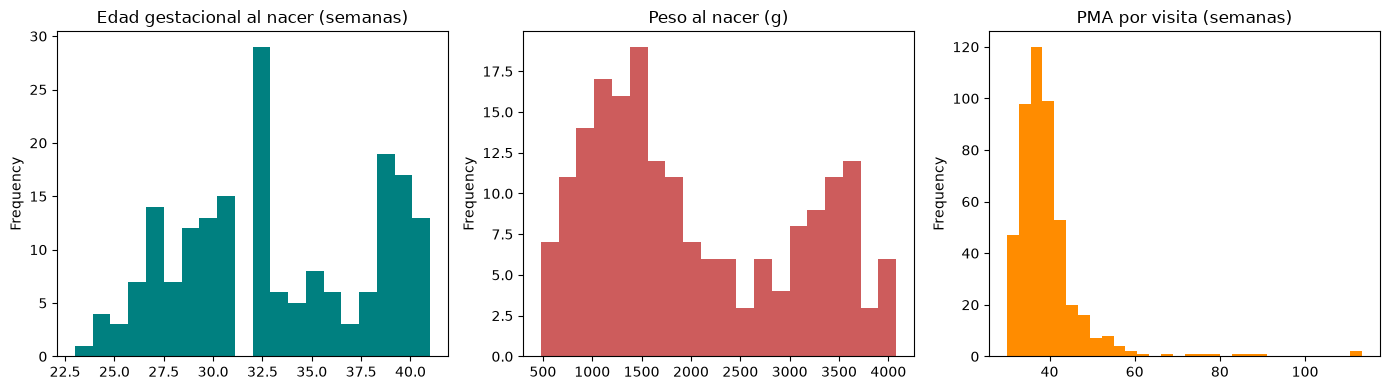

GA (pacientes): {'min': 23.0, 'mean': 33.180851063829785, 'max': 41.0}
BW (pacientes): {'min': 480.0, 'mean': 2016.5691489361702, 'max': 4080.0}
PMA (visitas): {'min': 30.0, 'mean': 39.476977567886664, 'max': 113.42857142857143}


In [9]:
# GA y BW son por paciente (constantes entre sus visitas); PMA varia por visita
patient_level = db.drop_duplicates("id")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
patient_level["ga"].plot(kind="hist", bins=20, ax=axes[0], color="teal")
axes[0].set_title("Edad gestacional al nacer (semanas)")
patient_level["bw"].plot(kind="hist", bins=20, ax=axes[1], color="indianred")
axes[1].set_title("Peso al nacer (g)")
db["pma"].plot(kind="hist", bins=30, ax=axes[2], color="darkorange")
axes[2].set_title("PMA por visita (semanas)")
plt.tight_layout()
plt.show()

print("GA (pacientes):", patient_level["ga"].describe()[["min", "mean", "max"]].to_dict())
print("BW (pacientes):", patient_level["bw"].describe()[["min", "mean", "max"]].to_dict())
print("PMA (visitas):", db["pma"].describe()[["min", "mean", "max"]].to_dict())

## Distribucion de diagnostico y Plus

El codigo de diagnostico (DG) mezcla estadios reales de ROP con hallazgos oculares que **no son ROP** (hemorragia, hamartoma, hipoplasia del nervio optico, toxoplasmosis) - hay que filtrarlos antes de usar esto como "estadio".

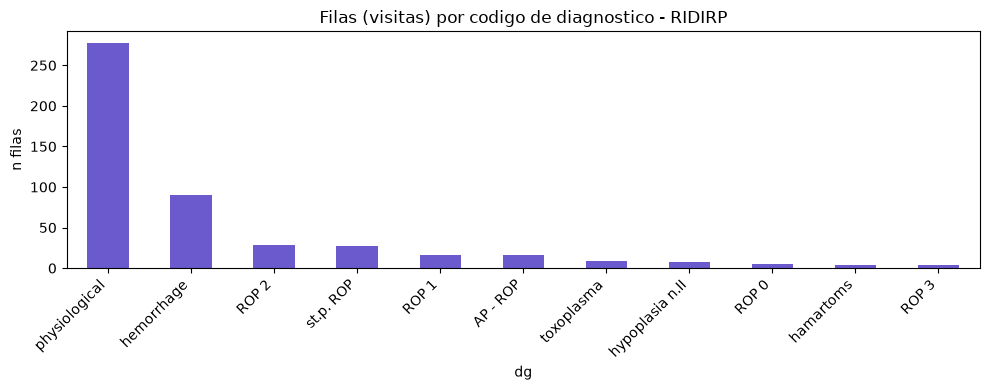

dg
physiological      278
hemorrhage          90
ROP 2               28
st.p. ROP           27
ROP 1               16
AP - ROP            16
toxoplasma           9
hypoplasia n.II      7
ROP 0                5
hamartoms            4
ROP 3                4
Name: count, dtype: int64

In [10]:
dg_names = dict(zip(diagnosis["DIAGNOSIS_ID"], diagnosis["DIAGNOSIS"]))
dg_counts = db["dg"].map(dg_names).value_counts()

fig, ax = plt.subplots(figsize=(10, 4))
dg_counts.plot(kind="bar", ax=ax, color="slateblue")
ax.set_title("Filas (visitas) por codigo de diagnostico - RIDIRP")
ax.set_ylabel("n filas")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
dg_counts

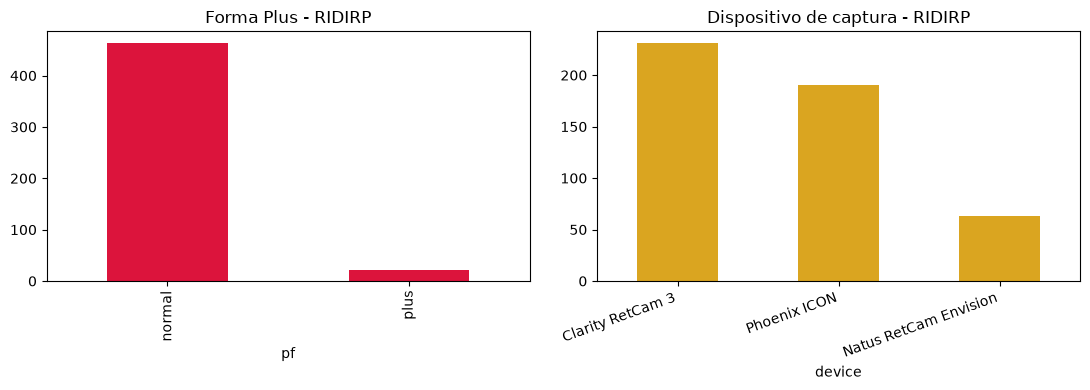

Plus: {'normal': 463, 'plus': 21}
ATENCION: no hay ningun caso 'pre-plus' en todo el dataset (0 filas).


In [11]:
pf_names = dict(zip(plus_form["PLUS FORM ID"], plus_form["PLUS FORM"]))
pf_counts = db["pf"].map(pf_names).value_counts()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
pf_counts.plot(kind="bar", ax=axes[0], color="crimson")
axes[0].set_title("Forma Plus - RIDIRP")

dev_names = dict(zip(devices["DEVICE ID"], devices["DEVICE"]))
db["device"].map(dev_names).value_counts().plot(kind="bar", ax=axes[1], color="goldenrod")
axes[1].set_title("Dispositivo de captura - RIDIRP")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

print("Plus:", pf_counts.to_dict())
print("ATENCION: no hay ningun caso 'pre-plus' en todo el dataset (0 filas).")

### Plus a nivel de paciente real (tras limpiar las filas no-ROP) - mucho mas extremo de lo que sugiere el conteo de imagenes

El grafico de arriba (629 imagenes "Plus" de 4.709 tras quitar las no-ROP) puede dar la impresion de que hay una cantidad razonable de casos Plus. A nivel de **paciente real** la historia es otra - lo verificamos cargando `datasets/clean/RIDIRP.parquet` (la salida de `clean_ridirp.py`).

--- por imagen ---
plus
Normal    4080
Plus       629
Name: count, dtype: int64

--- por bag (visita) ---
plus
Normal    353
Plus       21
Name: count, dtype: int64

--- por paciente real (150 pacientes en total tras limpiar) ---
pacientes con AL MENOS una visita Plus: 3  -> ['RIDIRP_043', 'RIDIRP_138', 'RIDIRP_139']
pacientes con AL MENOS una visita Normal: 149
pacientes con ambas (la enfermedad cambio entre visitas): 2  -> ['RIDIRP_138', 'RIDIRP_139']


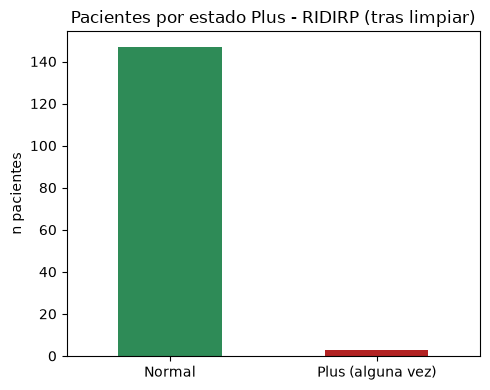

In [12]:
clean = pd.read_parquet(ROOT / "datasets" / "clean" / "RIDIRP.parquet")

print("--- por imagen ---")
print(clean["plus"].value_counts(dropna=False))
print("\n--- por bag (visita) ---")
print(clean.drop_duplicates("bag_id")["plus"].value_counts(dropna=False))

plus_patients = set(clean[clean["plus"] == "Plus"]["patient_id_global"].unique())
normal_patients = set(clean[clean["plus"] == "Normal"]["patient_id_global"].unique())

print(f"\n--- por paciente real ({clean['patient_id_global'].nunique()} pacientes en total tras limpiar) ---")
print(f"pacientes con AL MENOS una visita Plus: {len(plus_patients)}  -> {sorted(plus_patients)}")
print(f"pacientes con AL MENOS una visita Normal: {len(normal_patients)}")
print(f"pacientes con ambas (la enfermedad cambio entre visitas): {len(plus_patients & normal_patients)}  -> {sorted(plus_patients & normal_patients)}")

fig, ax = plt.subplots(figsize=(5, 4))
pd.Series({"Normal": len(normal_patients - plus_patients), "Plus (alguna vez)": len(plus_patients)}).plot(
    kind="bar", ax=ax, color=["seagreen", "firebrick"]
)
ax.set_title("Pacientes por estado Plus - RIDIRP (tras limpiar)")
ax.set_ylabel("n pacientes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Hallazgo:** solo **3 de 150 pacientes (2%)** tienen alguna vez `Plus` - `RIDIRP_043`, `RIDIRP_138`, `RIDIRP_139`. Las 629 imagenes "Plus" no son 629 casos independientes: son principalmente el paciente 043 (16 visitas, AP-ROP, Plus en todas) repetido muchas veces, mas un puñado de visitas de los otros dos pacientes (que ademas tienen visitas `Normal` tambien, porque su enfermedad progreso y luego regreso - son los mismos casos de regresion que vimos en la seccion de "pacientes con muchas visitas").

**Verificado contra las otras fuentes (detalle completo en `system/eda/README.md`, seccion "Plus/Pre-Plus a nivel de paciente real"):** al unir con FARFUM (35 pacientes reales con Pre-Plus/Plus) el pool combinado queda en 38 pacientes positivos - deja de ser un problema de diversidad casi inexistente y pasa a ser un desbalance de frecuencia normal (resoluble con Focal Loss/sampler). ROP-VL no aporta nada a esta tarea (no tiene columna de Plus). Sigue valiendo la pena, al hacer el Group K-Fold, verificar explicitamente que esos 38 pacientes queden repartidos entre folds en vez de asumir que el azar lo resuelve.

## Problema de datos encontrado: columna `series` mal asignada (dispositivo 3)

La columna `SERIE NUMBER (S)` del xlsx **no es confiable como llave de union** con los archivos de imagen para ~31 filas, todas del dispositivo 3 (Natus RetCam Envision): varias visitas con PMA distinto comparten el mismo numero de serie en vez de incrementar. Ejemplo real, paciente 146.

In [13]:
# xlsx: 4 filas, TODAS con series=4 pero PMA distinto -> mal asignado
print("Filas del xlsx para el paciente 146:")
display(db[db["id"] == 146][["id", "pma", "dg", "series", "device"]])

# En los archivos reales, esas 4 visitas SI estan numeradas correctamente 1,2,3,4
fnames_146 = sorted(p.name for p in EXTRACTED_DIR.glob("146_*.jpg"))
series_en_archivo = sorted(set(re.search(r"_S(\d+)_", f).group(1) for f in fnames_146))
pa_en_archivo = sorted(set(re.search(r"_PA(\d+)_", f).group(1) for f in fnames_146), key=int)
print("\nSeries presentes en los nombres de archivo:", series_en_archivo)
print("PA presentes en los nombres de archivo:", pa_en_archivo)
print("\n-> Solucion aplicada en dataset_build: alinear por PMA ascendente, no por la columna 'series' del xlsx.")

Filas del xlsx para el paciente 146:


,id,pma,dg,series,device
425,146,34.428571,3,4,3
426,146,35.285714,3,4,3
427,146,36.000000,4,4,3
428,146,37.000000,4,4,3



Series presentes en los nombres de archivo: ['01', '02', '03', '04']
PA presentes en los nombres de archivo: ['34', '35', '36', '37']

-> Solucion aplicada en dataset_build: alinear por PMA ascendente, no por la columna 'series' del xlsx.


## Por que usamos `images_stack_without_captions.zip` y no `images.zip`

RIDIRP trae 3 copias de las mismas imagenes. Comparamos hashes MD5 de un mismo archivo entre las 3 para decidir cual usar (esto abre los .zip originales, puede tardar unos segundos la primera vez).

In [14]:
# Imagen de un paciente con dispositivo 2 (Phoenix ICON) - ahi es donde aparece el overlay de texto
fname = "098_M_GA27_BW900_PA33_DG0_PF0_D2_S02_1.jpg"

z_images = zipfile.ZipFile(RAW_DIR / "images.zip")
z_stack = zipfile.ZipFile(RAW_DIR / "images_stack.zip")
z_clean = zipfile.ZipFile(RAW_DIR / "images_stack_without_captions.zip")

h_images = hashlib.md5(z_images.read(f"images/098/02/{fname}")).hexdigest()
h_stack = hashlib.md5(z_stack.read(f"images_stack/{fname}")).hexdigest()
h_clean = hashlib.md5(z_clean.read(f"images_stack_without_captions/{fname}")).hexdigest()

print("images.zip                       :", h_images, z_images.getinfo(f"images/098/02/{fname}").file_size, "bytes")
print("images_stack.zip                 :", h_stack, z_stack.getinfo(f"images_stack/{fname}").file_size, "bytes")
print("images_stack_without_captions.zip:", h_clean, z_clean.getinfo(f"images_stack_without_captions/{fname}").file_size, "bytes")
print("\nimages.zip == images_stack.zip (ambas CON texto quemado)?", h_images == h_stack)
print("images_stack_without_captions.zip es distinta (mas liviana, SIN texto)?", h_clean != h_stack)

images.zip                       : 64e55b19429c27419288610fa6e63b1b 642748 bytes
images_stack.zip                 : 64e55b19429c27419288610fa6e63b1b 642748 bytes
images_stack_without_captions.zip: 61e8857634cf8633d280b930cb815fe4 615319 bytes

images.zip == images_stack.zip (ambas CON texto quemado)? True
images_stack_without_captions.zip es distinta (mas liviana, SIN texto)? True


## Imagenes por visita (tamano del bag de MIL) y muestra visual

Total imagenes: 6004  | Total bags (paciente, serie): 484
count    484.000000
mean      12.404959
std        7.173483
min        2.000000
25%        8.000000
50%       12.000000
75%       15.000000
max       58.000000
dtype: float64


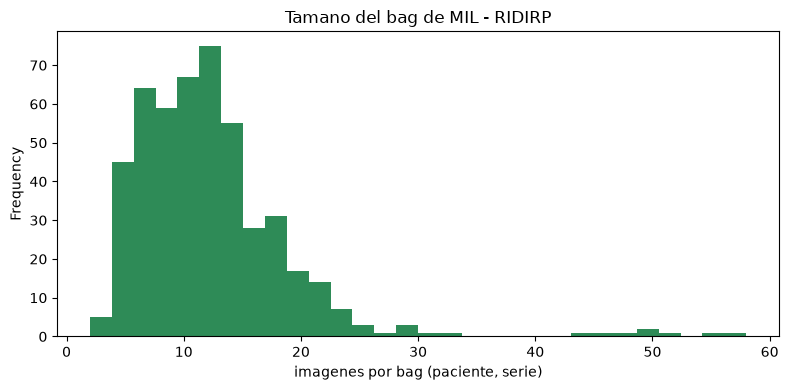

In [15]:
pat = re.compile(r"^(\d+)_[MF]_GA\d+_BW\d+_PA\d+_DG\d+_PF\d+_D\d+_S(\d+)_\d+\.jpg$")
bag_counts = Counter()
for p in EXTRACTED_DIR.glob("*.jpg"):
    m = pat.match(p.name)
    if m:
        bag_counts[(m.group(1), m.group(2))] += 1

counts = pd.Series(list(bag_counts.values()))
print("Total imagenes:", counts.sum(), " | Total bags (paciente, serie):", len(counts))
print(counts.describe())

fig, ax = plt.subplots()
counts.plot(kind="hist", bins=30, ax=ax, color="seagreen")
ax.set_xlabel("imagenes por bag (paciente, serie)")
ax.set_title("Tamano del bag de MIL - RIDIRP")
plt.tight_layout()
plt.show()

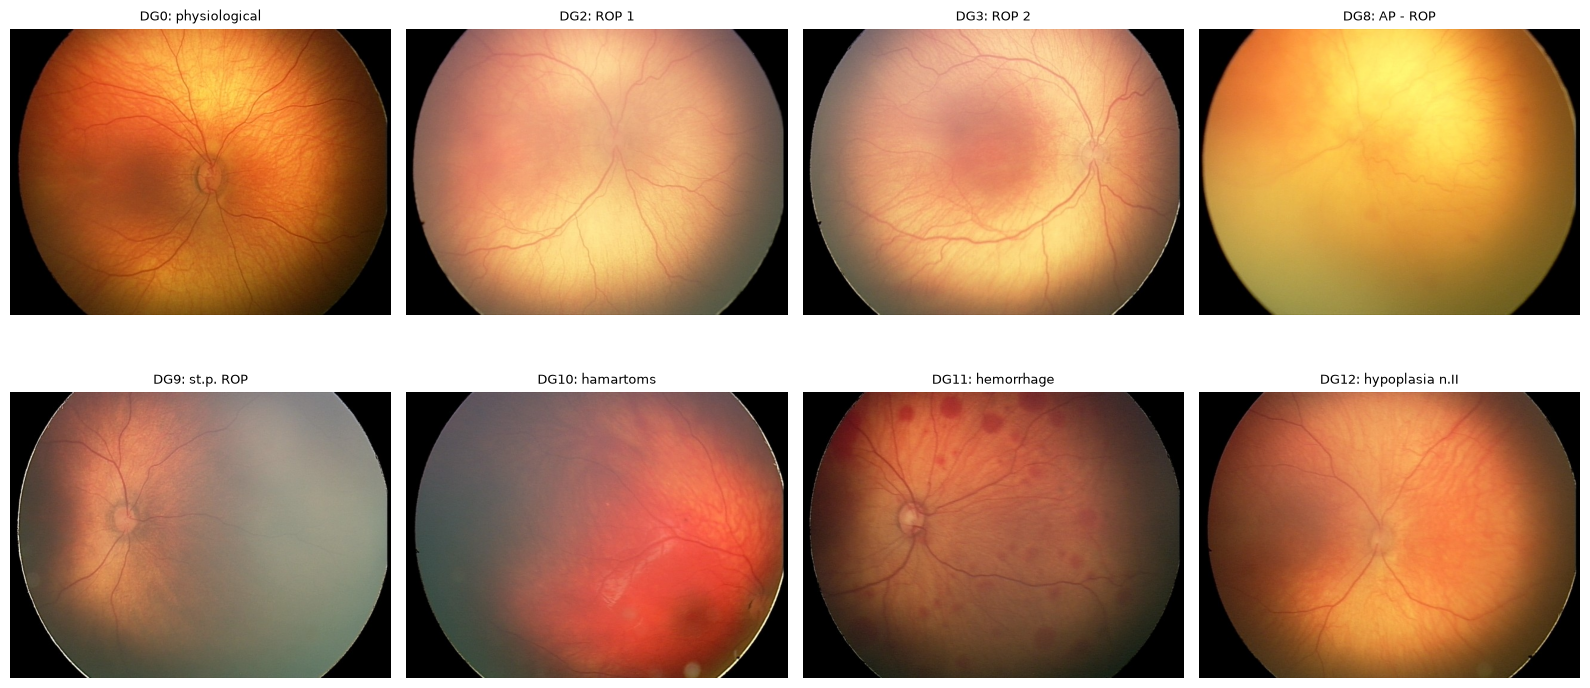

In [16]:
# Muestra visual: una imagen de cada diagnostico (cuando existe), para tener una referencia real
sample_files = sorted(EXTRACTED_DIR.glob("*.jpg"))
by_dg = {}
for p in sample_files:
    m = re.search(r"_DG(\d+)_", p.name)
    if m:
        dg = int(m.group(1))
        by_dg.setdefault(dg, p)
    if len(by_dg) >= 8:
        break

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax in axes.flat:
    ax.axis("off")
for ax, (dg, path) in zip(axes.flat, sorted(by_dg.items())):
    img = Image.open(path)
    ax.imshow(img)
    ax.set_title(f"DG{dg}: {dg_names.get(dg, '?')}", fontsize=9)
plt.tight_layout()
plt.show()

## Valores Nulos

Tres niveles distintos de "nulo" a revisar antes de escribir `clean_ridirp.py`:
1. Nulos en el xlsx crudo (celdas vacias de verdad).
2. Nulos que van a aparecer en las columnas derivadas (`stage`, `plus`) por las decisiones de mapeo del DG ya discutidas.
3. Integridad del cruce xlsx <-> archivos de imagen (una fila sin imagenes, o una imagen sin fila, tambien séria un "nulo" silencioso si no se detecta).

In [17]:
print("--- 1. Nulos en el xlsx crudo (hoja 'database', 484 filas) ---")
print(db.isna().sum())
print()
print("Sin celdas vacias en ninguna columna. Tampoco hay valores sospechosos:")
print("  ga<=0:", (db["ga"] <= 0).sum(), " | bw<=0:", (db["bw"] <= 0).sum(),
      " | pma<=0:", (db["pma"] <= 0).sum(), " | pma<ga:", (db["pma"] < db["ga"]).sum(),
      " | filas duplicadas:", db.duplicated().sum())

--- 1. Nulos en el xlsx crudo (hoja 'database', 484 filas) ---
id        0
sex       0
ga        0
bw        0
pma       0
dg        0
pf        0
device    0
series    0
dtype: int64

Sin celdas vacias en ninguna columna. Tampoco hay valores sospechosos:
  ga<=0: 0  | bw<=0: 0  | pma<=0: 0  | pma<ga: 0  | filas duplicadas: 0


--- 2. Nulos derivados (a nivel de FILA del xlsx, 484 filas; a nivel de IMAGEN el % es el mismo porque dg es constante por fila/visita) ---
stage nulo: 153 (31.6%)
plus nulo:  110 (22.7%)

Desglose de 'stage' nulo, por razon (diagnostico original):


diagnostico
hemorrhage         90
st.p. ROP          27
AP - ROP           16
toxoplasma          9
hypoplasia n.II     7
hamartoms           4
Name: count, dtype: int64

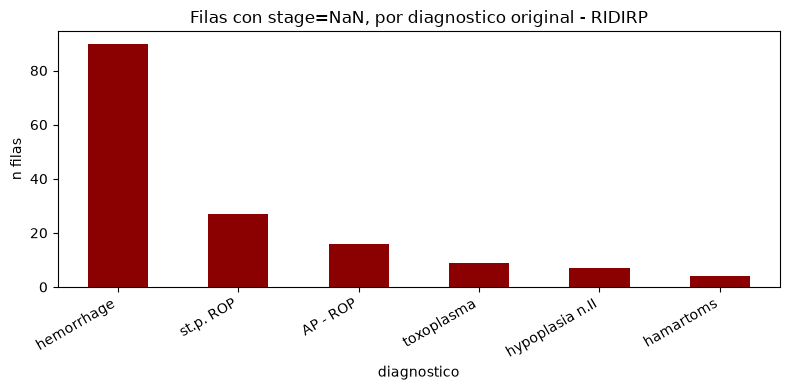

In [18]:
DG_TO_STAGE = {0: 0, 1: 0, 2: 1, 3: 2, 4: 3, 5: 4, 6: 4, 7: 5}
NON_ROP_CODES = {10, 11, 12, 13}

db["stage"] = db["dg"].map(DG_TO_STAGE)
db["is_rop_eligible"] = ~db["dg"].isin(NON_ROP_CODES)
db["diagnostico"] = db["dg"].map(dg_names)

n = len(db)
stage_null = db["stage"].isna().sum()
plus_null = (~db["is_rop_eligible"]).sum()

print(f"--- 2. Nulos derivados (a nivel de FILA del xlsx, {n} filas; a nivel de IMAGEN el % es el mismo porque dg es constante por fila/visita) ---")
print(f"stage nulo: {stage_null} ({100*stage_null/n:.1f}%)")
print(f"plus nulo:  {plus_null} ({100*plus_null/n:.1f}%)")
print()
print("Desglose de 'stage' nulo, por razon (diagnostico original):")
display(db[db["stage"].isna()]["diagnostico"].value_counts())

fig, ax = plt.subplots(figsize=(8, 4))
db[db["stage"].isna()]["diagnostico"].value_counts().plot(kind="bar", ax=ax, color="darkred")
ax.set_title("Filas con stage=NaN, por diagnostico original - RIDIRP")
ax.set_ylabel("n filas")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [19]:
# 3. Integridad del cruce xlsx <-> archivos (usando la misma alineacion por rank
# cronologico de PMA que aplica dataset_build, por el bug de la columna 'series')
img_pat = re.compile(r"^(\d+)_[MF]_GA\d+_BW\d+_PA\d+_DG\d+_PF\d+_D\d+_S(\d+)_\d+\.jpg$")

series_by_patient = {}
for p in EXTRACTED_DIR.glob("*.jpg"):
    m = img_pat.match(p.name)
    if m:
        pid, s = int(m.group(1)), int(m.group(2))
        series_by_patient.setdefault(pid, set()).add(s)

pacientes_xlsx = set(db["id"].unique())
pacientes_archivos = set(series_by_patient.keys())

rows_sin_imagenes = 0
for pid, group in db.groupby("id"):
    n_series_archivo = len(series_by_patient.get(pid, set()))
    if n_series_archivo != len(group):
        rows_sin_imagenes += abs(n_series_archivo - len(group))

print("--- 3. Integridad xlsx <-> archivos ---")
print("Pacientes en xlsx sin conteo de series que calce con los archivos:", rows_sin_imagenes)
print("Pacientes con imagenes pero sin fila en el xlsx:", len(pacientes_archivos - pacientes_xlsx))
print("Pacientes en el xlsx sin ninguna imagen extraida:", len(pacientes_xlsx - pacientes_archivos))
print("-> 0 en los tres: cruce perfecto, verificado ya en dataset_build tambien.")

--- 3. Integridad xlsx <-> archivos ---
Pacientes en xlsx sin conteo de series que calce con los archivos: 0
Pacientes con imagenes pero sin fila en el xlsx: 0
Pacientes en el xlsx sin ninguna imagen extraida: 0
-> 0 en los tres: cruce perfecto, verificado ya en dataset_build tambien.


## ¿Un bag puede tener mas de un resultado? (verificado contra `clean_ridirp.parquet` ya construido)

En FARFUM encontramos que, antes de reconciliar, un mismo paciente podia tener `stage`/`treatment`/`label` distintos entre sus propias imagenes (9/9/3 pacientes) - porque ahi 5 medicos opinan independientemente por imagen. Verificamos si RIDIRP tiene el mismo riesgo. **Esta celda corre contra el parquet ya generado por `clean_ridirp.py`** (no contra el xlsx crudo), asumiendo que ya se ejecuto ese script.

In [20]:
clean_path = ROOT / "datasets" / "clean" / "RIDIRP.parquet"
if not clean_path.exists():
    print(f"No se encontro {clean_path} - correr primero system/dataset_build/clean/clean_ridirp.py")
else:
    clean = pd.read_parquet(clean_path)

    def n_unique_nonnull(s):
        return s.dropna().nunique()

    g = clean.groupby("bag_id").agg(stage_u=("stage", n_unique_nonnull), plus_u=("plus", n_unique_nonnull))
    bad = g[(g > 1).any(axis=1)]
    print(f"bags de RIDIRP con mas de un resultado: {len(bad)} de {len(g)}")

bags de RIDIRP con mas de un resultado: 0 de 374


**0 bags inconsistentes de 374, y por una razon estructural, no por suerte:** a diferencia de FARFUM (5 medicos opinando independientemente por imagen), en RIDIRP **cada visita viene de una sola fila del registro clinico** (no hay multiples raters) - esa fila se une por igual a todas las imagenes de esa visita, asi que por construccion nunca puede haber dos valores distintos dentro de un mismo bag. El problema que se encontro en FARFUM es especifico de tener multiples evaluadores humanos independientes por imagen; RIDIRP (y ROP-VL, revisado antes con el mismo resultado de 0 tras reconciliar) no tienen esa fuente de conflicto del mismo modo, o ya quedo resuelta en su propia reconciliacion.

## Resumen de hallazgos (datos) - RIDIRP

- **188 pacientes, 6.004 imagenes, 484 visitas (bags).** Unica fuente con PMA real por visita y profundidad longitudinal genuina (hasta 16 visitas en un mismo paciente).
- **Usar `images_stack_without_captions.zip`**, no `images.zip` (identica a `images_stack.zip`, ambas con texto de paciente/fecha quemado en el pixel para dispositivos 2 y 3).
- **La columna `series` del xlsx no es confiable** para ~31 filas del dispositivo 3 (numero repetido en vez de incremental) - alinear por PMA ascendente contra el numero de serie real del nombre de archivo.
- **0 casos "Pre-Plus"** en todo el dataset - solo Normal y Plus.
- El codigo de diagnostico mezcla ROP real con hallazgos no-ROP (hemorragia, hamartoma, hipoplasia, toxoplasmosis) y casos especiales no reducibles a la escala ordinal 0-5 (AP-ROP, status-post-ROP).
- No distingue ojo (OD/OI) dentro de una visita - limitacion estructural del dataset, no resoluble desde los metadatos.
- **Nulos (ver seccion dedicada arriba):** el xlsx crudo no tiene ninguna celda vacia ni fila duplicada (0 en las 484 filas x 9 columnas). Los nulos aparecen recien en las columnas derivadas: `stage` queda NaN en 153 filas (31.6%, por AP-ROP/status-post/diagnosticos no-ROP) y `plus` en 110 filas (22.7%, solo diagnosticos no-ROP). El cruce xlsx <-> archivos de imagen es perfecto (0 pacientes sin imagen, 0 imagenes sin fila).

## Decisiones de diseno discutidas (sesion de limpieza RIDIRP)

Antes de pasar a los demas datasets, quedan documentadas aqui las decisiones tomadas para RIDIRP especificamente - se aplicaran en el script `clean_ridirp.py` (nueva etapa intermedia: crudo -> dataset limpio individual -> unificado).

**1. Estrategia general de limpieza (nueva, aplica a los 4 datasets):**
Se agrega una etapa intermedia entre el dato crudo y el parquet unificado: un script de limpieza por dataset (`clean_<nombre>.py`) que resuelve las tablas de lookup (DG, Plus Form, Device), unifica el DG a estadio, y descarta columnas que no se van a usar (`device`). El balanceo de clases (weighted sampler / class weights) y cualquier data augmentation para compensar desbalance se deciden en la etapa de union, no antes - porque dependen de la distribucion combinada de las 3 fuentes clinicas, no de RIDIRP aislado.

**2. DG 8 (AP-ROP) y DG 9 (status-post-ROP): se incluyen, no se descartan.**
Ni la imagen ni el `plus` (PLUS FORM) se eliminan para estas filas - siguen siendo datos clinicos reales y valiosos (AP-ROP en particular son los casos mas severos y mas raros, perderlos empobrece el dataset). Lo unico que se excluye es su participacion en la cabeza de **Estadio**: `stage=NaN` para ambos, porque:
 - AP-ROP no se define por extension de la cresta (la base de la escala 0-5) sino por localizacion posterior + velocidad de progresion + simetria - forzarlo a un numero introduciria ruido semantico (puede "verse" leve en la escala ordinal y ser gravisimo igual).
 - Status-post es un ojo ya tratado/regresado - su imagen actual no representa enfermedad activa, asignarle un estadio actual seria enganoso.

**3. Pacientes con muchas visitas (9 de 188, >5 visitas) NO son outliers a excluir.**
Se verificaron sus trayectorias completas (celda de arriba): son casos reales y explicables, no errores de carga. Ejemplo: el paciente 55 (GA=38, casi a termino, 9 visitas) no es un caso de alto riesgo por prematuridad sino de **toxoplasmosis congenita** (DG=13 en las 9 visitas), que requiere seguimiento repetido sin relacion con ROP. Los pacientes 31 y 138 muestran progresion y **regresion** real de estadio entre visitas (ej. ROP2->ROP2->ROP1) - la severidad no es estrictamente monotona en el tiempo.
 - Recomendacion: incluirlos en el dataset final.
 - Cuidado a futuro (no implementado todavia, solo si se observa el problema en la practica): como el Group K-Fold agrupa por paciente, un paciente con 16 bags "pesa" mas en el gradiente de su fold que uno con 1 bag. Si el modelo muestra sobreajuste a estos 9 pacientes particulares, corregir con **sample weighting a nivel de bag** (peso = 1/n_visitas_del_paciente en la perdida, o un `WeightedRandomSampler` en el DataLoader) - no excluyendo pacientes.

**4. Bag (visita) vs. paciente real - confirmado, no se colapsa a nivel paciente.**
`bag_id` (la visita, ej. `RIDIRP_043_S01`) es la unidad de entrenamiento (MIL); `patient_id_global` (ej. `RIDIRP_043`) es la unidad que solo se usa para el Group K-Fold. El paciente 43 aporta 16 filas/bags distintos al parquet final, no una fila resumen.

**5. "MIL" vs. "MIL temporal" - son cosas distintas, aclarado.**
MIL (Cross-Attention por imagen + Attention Pooling) aplica a los 3 datasets clinicos por igual (cada uno agrupa sus imagenes en bags: RIDIRP por visita, FARFUM por paciente, ROP-VL por ojo+fecha). No se esta construyendo un modelo de secuencia a traves de las visitas (sin RNN/Transformer entre visitas) - cada visita sigue siendo una fila independiente. Lo "temporal" se reduce a que el PMA cambia por visita (vector clinico distinto en cada bag) y a que el Group K-Fold evita que visitas del mismo bebe crucen entre splits. **Pendiente:** revisar el nombre "Fase 3: MIL temporal y espacial" en el README principal, puede ser confuso.

**6. Solo RIDIRP es longitudinal en profundidad - no es una propiedad de los 4 datasets.**
RIDIRP: 2.57 visitas/paciente en promedio (hasta 16). FARFUM: 0% longitudinal (0 pacientes con mas de una sesion, verificado). ROP-VL: parcialmente, 17% de los pacientes (190/1116) tienen mas de una fecha, hasta 5 visitas, pero no es el diseno central del dataset.

**7. `device` (Clarity RetCam 3 / Phoenix ICON / Natus RetCam Envision): se conserva en `clean_ridirp.parquet`, pero se descarta en el unificado.**
Division de responsabilidades por capa: nunca es un feature de entrada del modelo (decision original), pero en el dataset limpio individual si se mantiene como `device_raw` (metadata), porque es barato conservarlo y sirve para un analisis de robustez (leave-one-device-out) que vale la pena hacer: RIDIRP tiene 3 dispositivos con distribucion desigual (RetCam 3: 231 filas, Phoenix ICON: 190, Natus Envision: 63), posible fuente de confounding si el dispositivo correlaciona con sitio/poblacion en vez de con la enfermedad - mas relevante aun porque el dispositivo 3 fue el que tenia el bug de la columna `series` (punto de la seccion anterior), lo que sugiere que ese flujo de datos puede tener otras particularidades. En el parquet **unificado** si se descarta por completo: ahi nunca seria feature de entrada, y ademas seria una columna casi siempre vacia (solo RIDIRP la tiene; a diferencia de PMA, que si se mantiene en el unificado porque el modelo si lo usa cuando esta disponible).

**8. Desbalance de clases - opciones evaluadas (se deciden en la etapa de union, no aqui):**
- Estadio: Focal Loss con pesos por clase (`alpha` inversamente proporcional a frecuencia) + `WeightedRandomSampler` a nivel de bag + Distance Penalty Matrix (para que confundir estadios adyacentes cueste menos que confundir extremos). Al unificar con ROP-VL (mejor balanceado, incluye Stage 4/5) el conjunto combinado queda menos sesgado que RIDIRP aislado.
- Plus: RIDIRP no tiene casos Pre-Plus, pero FARFUM aporta 479 casos reales (via la columna `Label`) - la clase no desaparece del pool global, solo esta ausente en esta fuente. Mismas tecnicas aplican al pool unificado.

**9. Que es MIL y por que no depende de la "temporalidad" (aclaracion de otra sesion, relevante para RIDIRP por ser la unica fuente longitudinal):**
MIL (Multiple Instance Learning) = un bag (conjunto de imagenes de **un mismo examen clinico**, mismo paciente mismo dia) comparte una sola etiqueta, sin saber cual imagen individual la determina - el modelo mira todas las imagenes del bag y decide en conjunto (Cross-Attention por imagen + Attention Pooling, tamano de bag variable). Esto es ortogonal a la longitudinalidad: en RIDIRP, cada una de las 16 visitas del paciente 43 es un **bag independiente**, no 16 fotos dentro de un mismo bag - no hay modelo de secuencia entre visitas, cada visita se entrena por separado.
 - **Caso de uso de produccion confirmado:** el medico sube 1 o varias fotos del **examen de hoy** (mismo encuentro clinico) y el sistema predice el estado actual - esto es exactamente un bag, sin necesitar historial de visitas anteriores. No se requiere PMA ni ninguna variable temporal para que esto funcione: un bag de FARFUM (sin PMA) se procesa igual que uno de RIDIRP (con PMA), el Cross-Attention simplemente usa el vector clinico que este disponible.
 - Confirmado explicitamente: **no** se va a construir una capacidad de "subir fotos de examenes anteriores para usar el historial real" - queda fuera de scope. Si se quisiera en el futuro, la opcion mas simple seria agregar features clinicos derivados (ej. "ultimo estadio registrado") al vector de la visita actual, no un modelo de secuencia entre bags.
 - Confirmar PMA solo en RIDIRP, verificado de nuevo: FARFUM no tiene PMA ni fecha de examen/nacimiento; ROP-VL tiene fecha de examen pero no fecha de nacimiento, asi que tampoco es calculable. No afecta a MIL (que no depende de PMA), solo significa que esos datasets no aprovechan la parte "dinamica" del vector clinico.
 - **Pendiente:** el README principal (seccion 4, Arquitectura) no menciona el caso de uso de produccion todavia - agregarlo ahi tambien para que quede como referencia central, no solo en este EDA.

**10. Nulos: por que no se imputan, y que se hace en su lugar.**
Los 3 niveles de nulo revisados arriba no son equivalentes:
 - **Nivel 1 (xlsx crudo):** 0 nulos reales en GA/BW/PMA/sexo/DG/PF/device - no hay nada que imputar, el dato de origen esta completo.
 - **Nivel 2 (`stage`/`plus` derivados):** no son "missing data" en el sentido clasico (un valor real que no se registro) - son exclusiones semanticas intencionales (la pregunta "que estadio tiene" no aplica a una hemorragia o a AP-ROP). Imputar aqui seria **peor** que dejar el hueco: inventaria una etiqueta falsa y meteria ruido real al entrenamiento. La tecnica correcta ya esta en el diseno: **enmascarar** la perdida por tarea y por muestra (`$m_i$` en la formula de perdida del README), no imputar.
 - **Nivel 3 (cruce xlsx<->imagenes):** verificacion de integridad de ingenieria, no estadistica - 0 problemas, nada que imputar.
 - **Decision derivada de esto:** las 110 filas (22.7%) con diagnostico no-ROP (hemorragia, hamartoma, hipoplasia, toxoplasmosis) quedarian con `stage=NaN` **y** `plus=NaN` **y** `treatment=NaN` simultaneamente - es decir, no aportan gradiente a ningun cabezal clinico. `clean_ridirp.py` las **elimina por completo** del parquet limpio (no solo se enmascaran) porque mantenerlas solo gastaria computo (pasar por ViT + Cross-Attention + Pooling + 3 cabezales) sin ningun beneficio de entrenamiento. AP-ROP y status-post SI se mantienen porque `plus` sigue siendo valido para ellas.

## Esquema final de `clean_ridirp.parquet`

Grano: una fila = una imagen. Filtro de filas: se descartan las 110 filas (484-110=374 restantes) con DG en {10,11,12,13} (no-ROP).

| Columna | Tipo | Contenido |
|---|---|---|
| `sample_id` | str | `RIDIRP_043_S01_1` |
| `bag_id` | str | `RIDIRP_043_S01` (visita, agrupador de MIL) |
| `patient_id_global` | str | `RIDIRP_043` (paciente real, para Group K-Fold) |
| `image_path` | str | ruta relativa a `datasets/extracted/` |
| `sexo` | str | M/F |
| `GA`, `BW` | float | constantes por paciente |
| `PMA` | float | real por visita (sin nulos) |
| `stage` | float, nullable | 0-5; NaN solo en AP-ROP/status-post (43 filas) |
| `plus` | str, nullable | Normal/Plus; 0 nulos tras el filtro (RIDIRP nunca tiene Pre-Plus) |
| `treatment` | nullable | siempre `None` (RIDIRP no tiene esta etiqueta) - columna vacia por consistencia de esquema con los otros 3 datasets limpios |
| `ap_rop`, `status_post_rop` | bool | flags para no perder la razon del `stage=NaN` |
| `device_raw` | int | metadata, NO feature de entrada - se descarta al construir el parquet unificado |
| `raw_diagnosis_code` | str | codigo DG original, trazabilidad |

`split`/`fold` siguen sin llenarse aqui, responsabilidad de la etapa de union.